### Import Required Libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

### Load the Dataset

In [2]:
df=pd.read_csv(r'C:\Users\DELL\Desktop\Bankruptcy_Prevention\Bankruptcy_prevention_Dataset.csv',sep=';')
df.head()

,industrial_risk,management_risk,financial_flexibility,credibility,competitiveness,operating_risk,class
0,0.5,1.0,0.0,0.0,0.0,0.5,bankruptcy
1,0.0,1.0,0.0,0.0,0.0,1.0,bankruptcy
2,1.0,0.0,0.0,0.0,0.0,1.0,bankruptcy
3,0.5,0.0,0.0,0.5,0.0,1.0,bankruptcy
4,1.0,1.0,0.0,0.0,0.0,1.0,bankruptcy


In [3]:
df.columns

Index(['industrial_risk', ' management_risk', ' financial_flexibility',
       ' credibility', ' competitiveness', ' operating_risk', ' class'],
      dtype='object')

### Clean column names

In [4]:
df.columns=df.columns.str.strip()

In [5]:
df['class']=df['class'].str.strip()

In [6]:
df.head()

,industrial_risk,management_risk,financial_flexibility,credibility,competitiveness,operating_risk,class
0,0.5,1.0,0.0,0.0,0.0,0.5,bankruptcy
1,0.0,1.0,0.0,0.0,0.0,1.0,bankruptcy
2,1.0,0.0,0.0,0.0,0.0,1.0,bankruptcy
3,0.5,0.0,0.0,0.5,0.0,1.0,bankruptcy
4,1.0,1.0,0.0,0.0,0.0,1.0,bankruptcy


### Understand the Dataset

In [7]:
df.shape

(250, 7)

In [8]:
df.columns

Index(['industrial_risk', 'management_risk', 'financial_flexibility',
       'credibility', 'competitiveness', 'operating_risk', 'class'],
      dtype='object')

In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 250 entries, 0 to 249
Data columns (total 7 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   industrial_risk        250 non-null    float64
 1   management_risk        250 non-null    float64
 2   financial_flexibility  250 non-null    float64
 3   credibility            250 non-null    float64
 4   competitiveness        250 non-null    float64
 5   operating_risk         250 non-null    float64
 6   class                  250 non-null    object 
dtypes: float64(6), object(1)
memory usage: 13.8+ KB


### Check the Missing Values

In [10]:
df.isnull().sum()

industrial_risk          0
management_risk          0
financial_flexibility    0
credibility              0
competitiveness          0
operating_risk           0
class                    0
dtype: int64

### Check Duplicate Records

In [11]:
df.duplicated().sum()

np.int64(147)

### Check unique values in every column

In [12]:
for col in df.columns:
    print(col, ":", df[col].unique())

industrial_risk : [0.5 0.  1. ]
management_risk : [1.  0.  0.5]
financial_flexibility : [0.  0.5 1. ]
credibility : [0.  0.5 1. ]
competitiveness : [0.  0.5 1. ]
operating_risk : [0.5 1.  0. ]
class : ['bankruptcy' 'non-bankruptcy']


### Descriptive statistical analysis

In [13]:
df.describe()

,industrial_risk,management_risk,financial_flexibility,credibility,competitiveness,operating_risk
count,250.000000,250.000000,250.000000,250.000000,250.000000,250.000000
mean,0.518000,0.614000,0.376000,0.470000,0.476000,0.570000
std,0.411526,0.410705,0.401583,0.415682,0.440682,0.434575
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,0.500000,0.000000,0.000000,0.000000,0.000000
50%,0.500000,0.500000,0.500000,0.500000,0.500000,0.500000
75%,1.000000,1.000000,0.500000,1.000000,1.000000,1.000000
max,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


In [14]:
# Summarize target Variable
df['class'].describe()

count                250
unique                 2
top       non-bankruptcy
freq                 143
Name: class, dtype: object

### Analyze the Target Variable 


In [15]:
df['class'].value_counts()

class
non-bankruptcy    143
bankruptcy        107
Name: count, dtype: int64

### Calculate class percentages

In [16]:
df['class'].value_counts(normalize=True)*100

class
non-bankruptcy    57.2
bankruptcy        42.8
Name: proportion, dtype: float64

### Visualize the target distribution

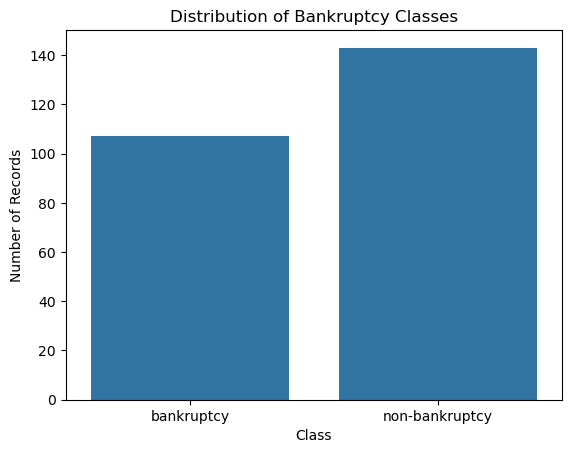

In [17]:
sns.countplot(data=df, x="class")
plt.title("Distribution of Bankruptcy Classes")
plt.xlabel("Class")
plt.ylabel("Number of Records")
plt.show()

In [18]:
#Select in the input Features
features=df.drop(columns='class').columns
features

Index(['industrial_risk', 'management_risk', 'financial_flexibility',
       'credibility', 'competitiveness', 'operating_risk'],
      dtype='object')

### Plot the distribution of every feature

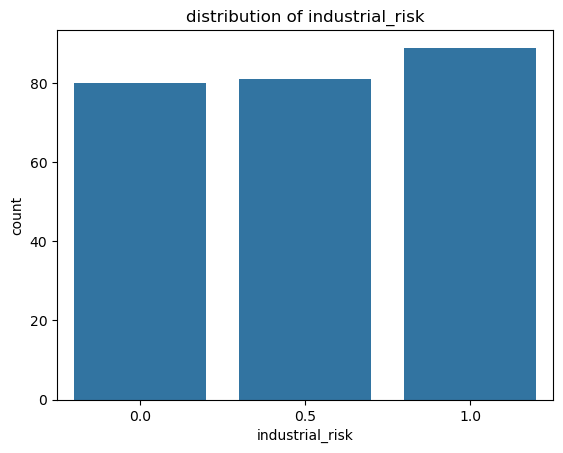

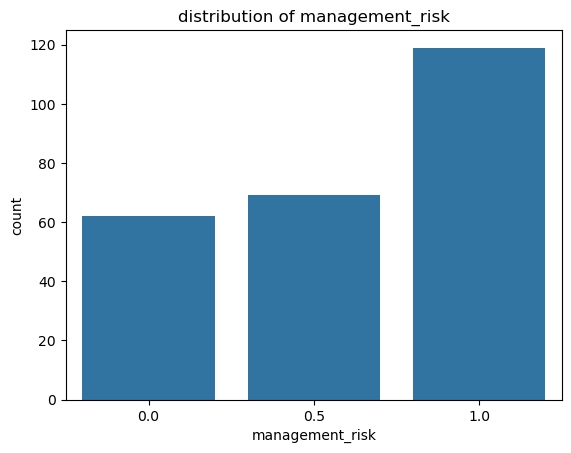

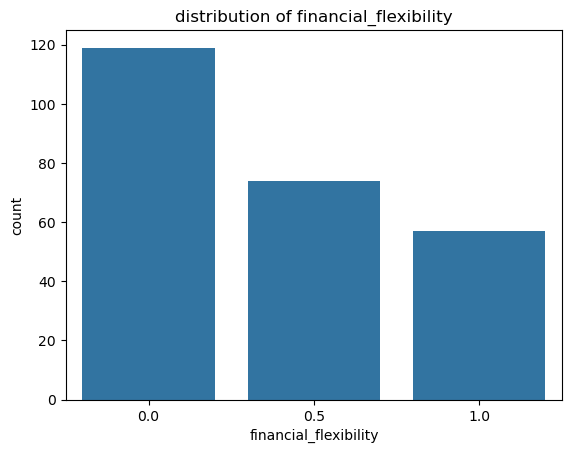

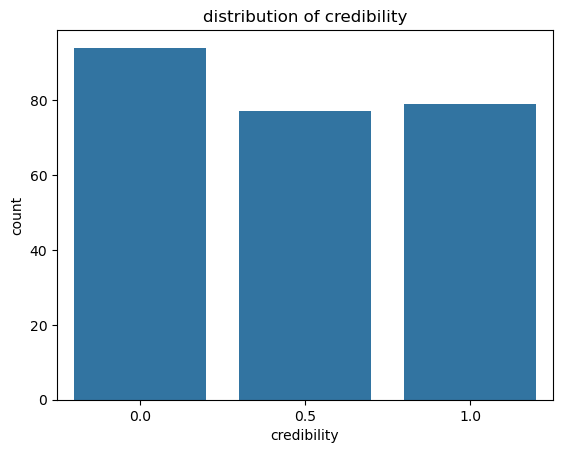

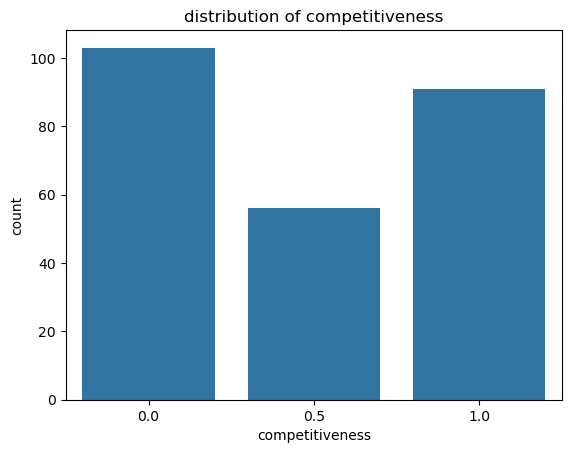

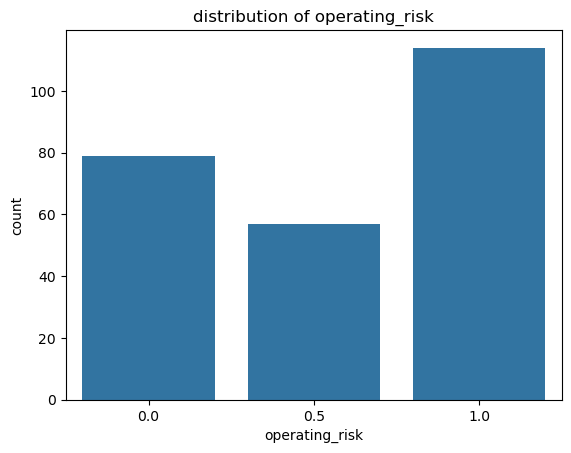

In [21]:
for col in features:
    sns.countplot(data=df,x=col)
    plt.title(f'distribution of {col}')
    plt.xlabel(col)
    plt.ylabel('count')
    plt.show()

### Compare Each feature with Bankruptcy Status

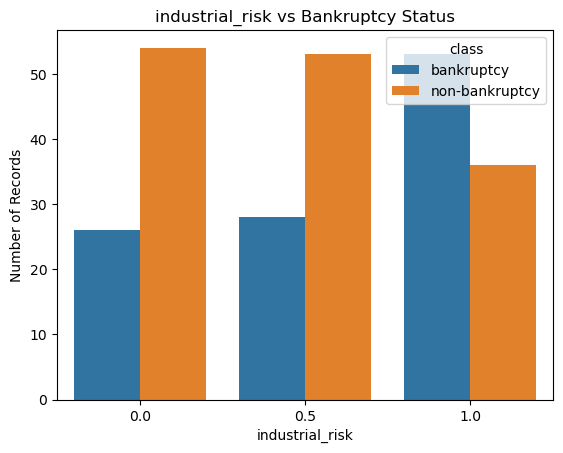

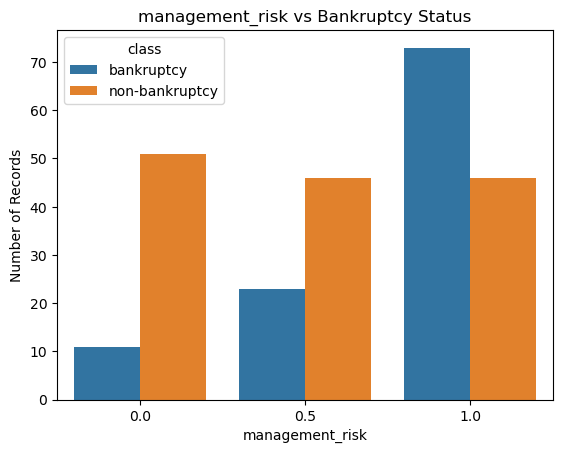

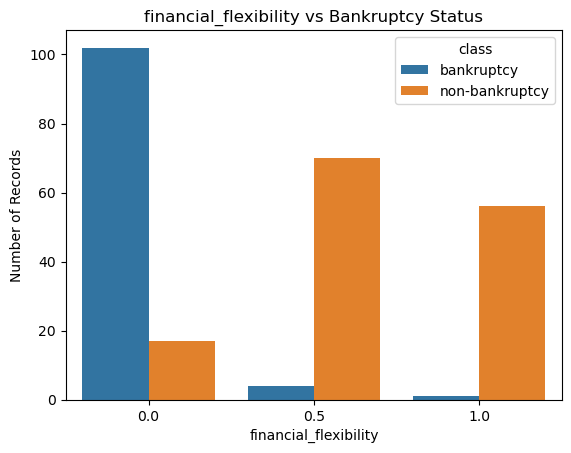

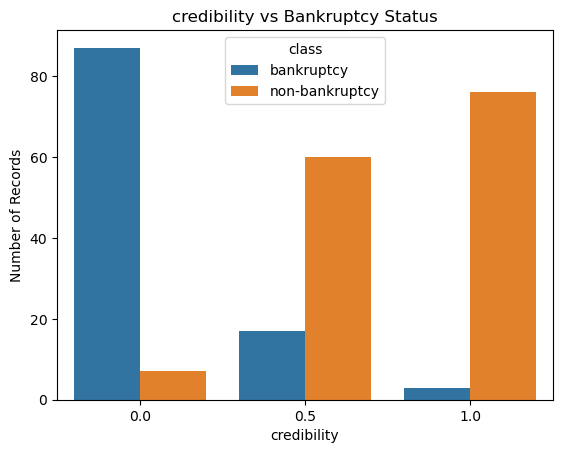

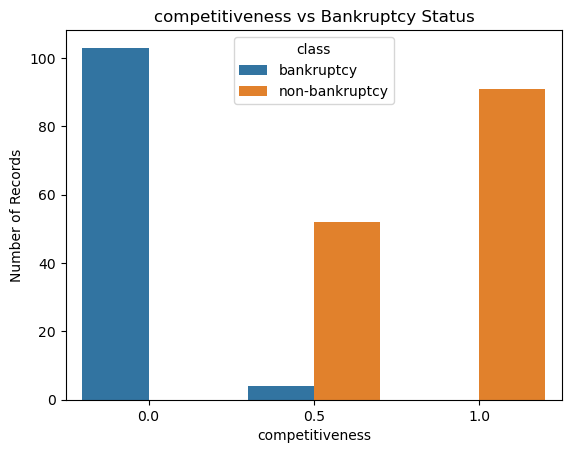

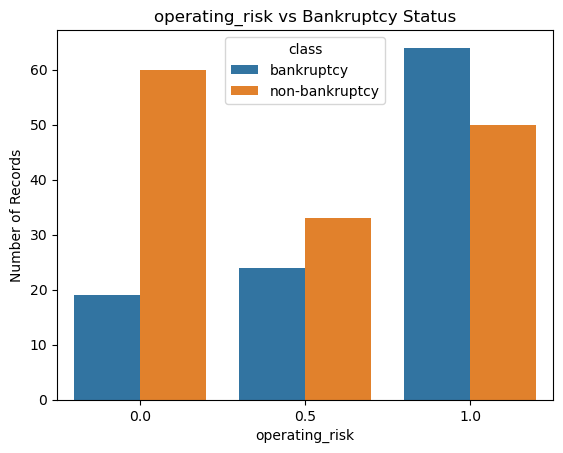

In [22]:
for col in features:
    sns.countplot(data=df,x=col,hue='class')
    plt.title(f"{col} vs Bankruptcy Status")
    plt.xlabel(col)
    plt.ylabel('Number of Records')
    plt.legend(title='class')
    plt.show()

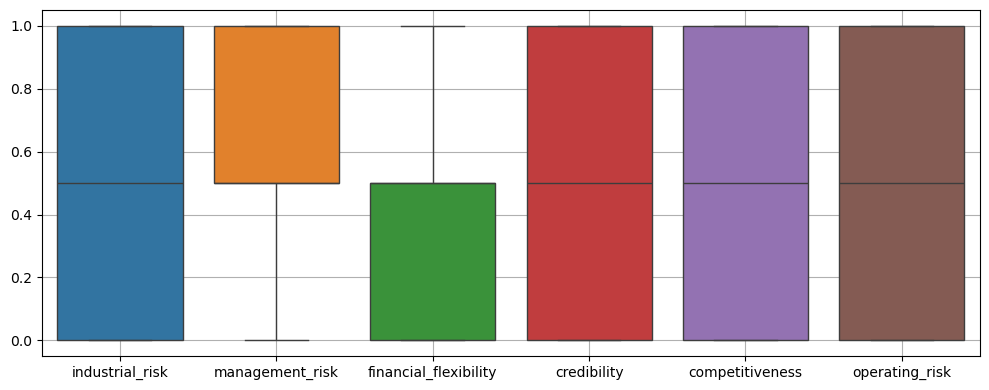

In [23]:
plt.figure(figsize=(10,4))
sns.boxplot(data=df.drop(columns='class'))
plt.grid(1)
plt.tight_layout()
plt.show()

### Calculate correlations between input features

In [22]:
correlation=df[features].corr()
correlation

,industrial_risk,management_risk,financial_flexibility,credibility,competitiveness,operating_risk
industrial_risk,1.000000,0.255127,-0.162624,-0.014438,-0.257814,0.144507
management_risk,0.255127,1.000000,-0.254845,-0.303341,-0.306568,0.213874
financial_flexibility,-0.162624,-0.254845,1.000000,0.524951,0.686612,-0.116903
credibility,-0.014438,-0.303341,0.524951,1.000000,0.675689,-0.288458
competitiveness,-0.257814,-0.306568,0.686612,0.675689,1.000000,-0.211383
operating_risk,0.144507,0.213874,-0.116903,-0.288458,-0.211383,1.000000


### Visualize the Correlation matrix

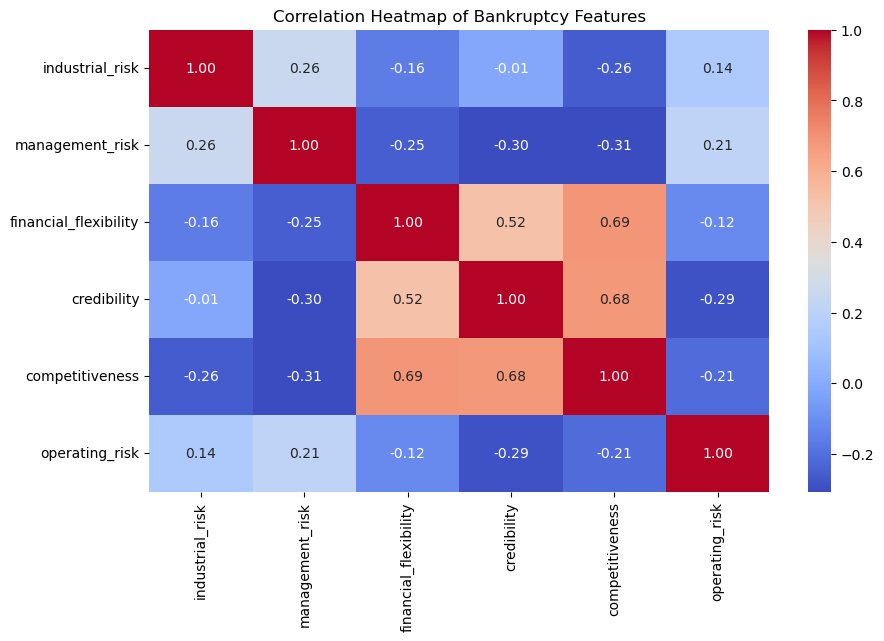

In [23]:
plt.figure(figsize=(10,6))
sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)
plt.title('Correlation Heatmap of Bankruptcy Features')
plt.show()

### Separate Input and Target Variables

In [24]:
X=df.drop('class',axis=1)
y=df['class']

In [25]:
X.shape

(250, 6)

In [26]:
y.shape

(250,)

### Data Transformation

In [27]:
from sklearn.preprocessing import StandardScaler,LabelEncoder
SS=StandardScaler()
SS_X=SS.fit_transform(X)
SS_X=pd.DataFrame(SS_X,columns=X.columns)
SS_X

,industrial_risk,management_risk,financial_flexibility,credibility,competitiveness,operating_risk
0,-0.043827,0.941732,-0.938172,-1.132941,-1.082310,-0.161400
1,-1.261256,0.941732,-0.938172,-1.132941,-1.082310,0.991457
2,1.173601,-1.497989,-0.938172,-1.132941,-1.082310,0.991457
3,-0.043827,-1.497989,-0.938172,0.072315,-1.082310,0.991457
4,1.173601,0.941732,-0.938172,-1.132941,-1.082310,0.991457
...,...,...,...,...,...,...
245,-1.261256,0.941732,1.556967,1.277572,1.191451,0.991457
246,1.173601,0.941732,0.309397,1.277572,1.191451,-1.314257
247,-1.261256,0.941732,1.556967,0.072315,0.054570,-1.314257
248,1.173601,-1.497989,0.309397,1.277572,0.054570,-1.314257


In [32]:
LE=LabelEncoder()
df['class']=LE.fit_transform(df['class'])
df['class'].value_counts()
   # 0 = bankruptcy,1=non-bankruptcy

class
1    143
0    107
Name: count, dtype: int64

In [33]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 250 entries, 0 to 249
Data columns (total 7 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   industrial_risk        250 non-null    float64
 1   management_risk        250 non-null    float64
 2   financial_flexibility  250 non-null    float64
 3   credibility            250 non-null    float64
 4   competitiveness        250 non-null    float64
 5   operating_risk         250 non-null    float64
 6   class                  250 non-null    int64  
dtypes: float64(6), int64(1)
memory usage: 13.8 KB


In [34]:
df['class'].value_counts() 

class
1    143
0    107
Name: count, dtype: int64

### Data Partition

In [81]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)
print('X_train:',X_train.shape)
print('X_test:',X_test.shape)
print('y_train:',y_train.shape)
print('y_test:',y_test.shape)

X_train: (200, 6)
X_test: (50, 6)
y_train: (200,)
y_test: (50,)


### Create Logistic Regression Model

In [82]:
from sklearn.linear_model import LogisticRegression
model=LogisticRegression()

In [83]:
#fit the model
model.fit(X_train,y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,100
,multi_class,'deprecated'


In [84]:
#predict the Model
y_pred_test=model.predict(X_test)

### Model Evaluation

In [85]:
from sklearn.metrics import accuracy_score,precision_score,recall_score,f1_score,classification_report,confusion_matrix,log_loss

In [86]:
accuracy=accuracy_score(y_test,y_pred_test)
print('Accuracy:',accuracy)

Accuracy: 1.0


In [87]:
Precision=precision_score(y_test,y_pred_test)
print('Precision:',Precision)

Precision: 1.0


In [88]:
recall=recall_score(y_test,y_pred_test)
print('Recall:',recall)

Recall: 1.0


In [117]:
f1=f1_score(y_test,y_pred_test)
print('F1_score:',f1)

F1_score: 1.0


In [114]:
from sklearn.model_selection import cross_val_score

logistic_scores = cross_val_score(
    model,
    X,
    y,
    cv=5,
    scoring='accuracy'
)

print(logistic_scores)
print("Mean Accuracy:", logistic_scores.mean())

[1.   1.   1.   0.98 1.  ]
Mean Accuracy: 0.9960000000000001


In [90]:
print(classification_report(y_test,y_pred_test))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00        21
           1       1.00      1.00      1.00        29

    accuracy                           1.00        50
   macro avg       1.00      1.00      1.00        50
weighted avg       1.00      1.00      1.00        50



In [91]:
print(confusion_matrix(y_test,y_pred_test))

[[21  0]
 [ 0 29]]


In [92]:
print("Train Accuracy:", model.score(X_train, y_train))
print("Test Accuracy:", model.score(X_test, y_test))

Train Accuracy: 0.995
Test Accuracy: 1.0


### Decision Tree Classifier

In [93]:
from sklearn.tree import DecisionTreeClassifier
dt=DecisionTreeClassifier(criterion='gini')
dt.fit(X_train,y_train)

,criterion,'gini'
,splitter,'best'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,None
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None


In [94]:
# Set up ShuffleSplit cross-validator

from sklearn.model_selection import ShuffleSplit,cross_validate

shuffle_split=ShuffleSplit(n_splits=100,test_size=0.2,random_state=42)

cv_results=cross_validate(dt,X,y,cv=shuffle_split,scoring='accuracy',return_train_score=True)

test_scores_dt=cv_results['test_score']

print('Cross Validation-test accuracy:',np.round(test_scores_dt.mean(),2))

Cross Validation-test accuracy: 0.99


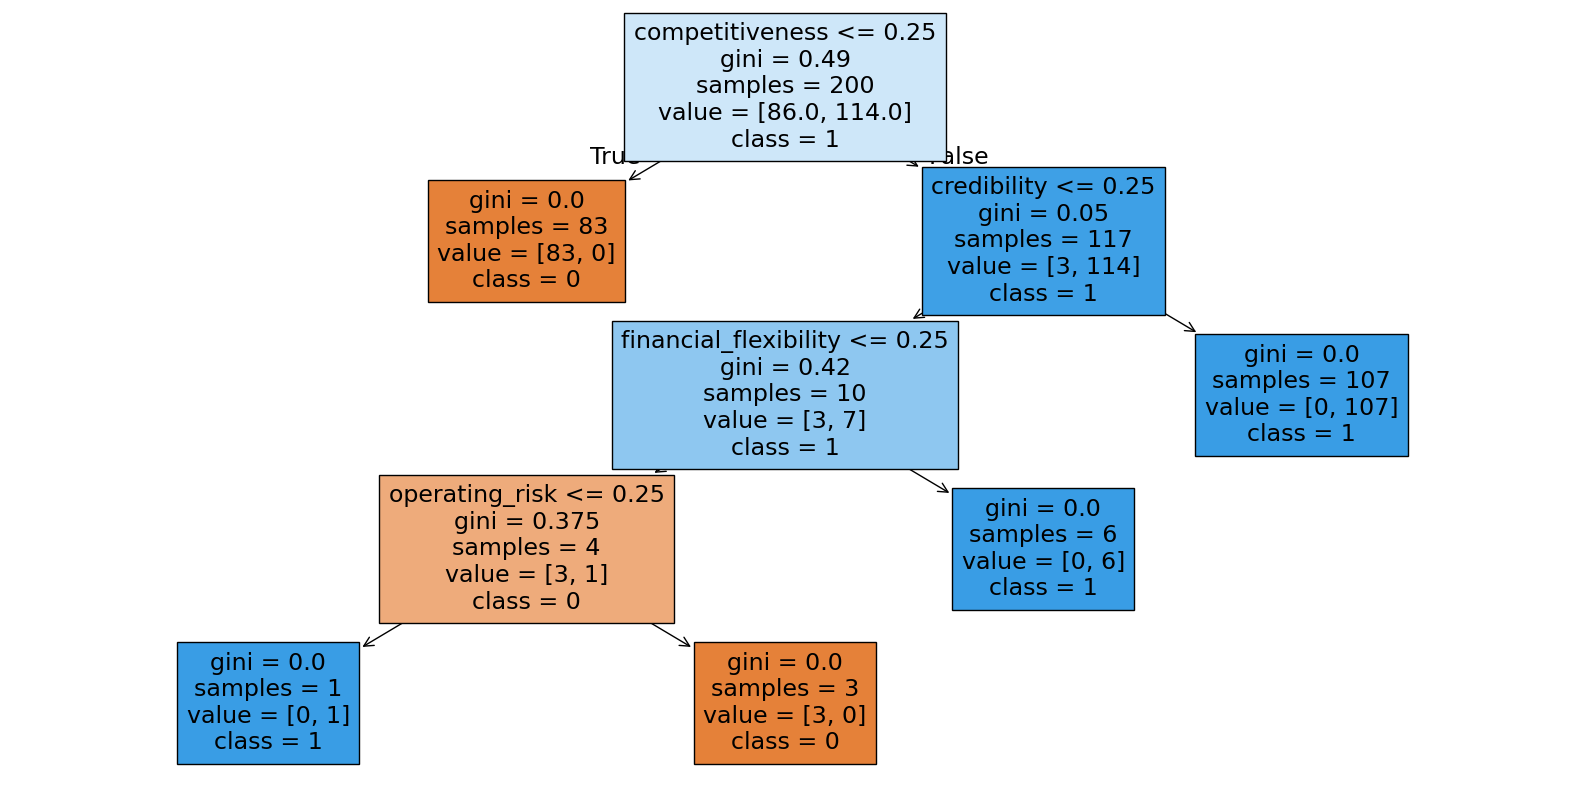

In [95]:
from sklearn.tree import plot_tree
import matplotlib.pyplot as plt
plt.figure(figsize=(20,10))
plot_tree(
    dt,
    filled=True,
    feature_names=X.columns,
    class_names=['0','1'],
)
plt.show()

### Random Forest

In [96]:
from sklearn.ensemble import RandomForestClassifier

In [97]:
rf_model=RandomForestClassifier(n_estimators=200,random_state=42,
                                max_samples=0.6,max_features=0.7,max_depth=10)

rf_model.fit(X_train,y_train)

y_pred_test_rf=rf_model.predict(X_test)
proba_rf=rf_model.predict_proba(X_test)[:,1]

In [98]:
test_accuracy_rf=accuracy_score(y_test,y_pred_test_rf)

print("Random Forest-Testing Accuracy:",np.round(test_accuracy_rf,2))

Random Forest-Testing Accuracy: 1.0


In [120]:
from sklearn.model_selection import cross_val_score

rf_scores = cross_val_score(
    rf_model,
    X,
    y,
    cv=5,
    scoring='accuracy'
)

print(rf_scores)
print("Rf- Accuracy:",rf_scores.mean())

[1.   1.   1.   0.98 1.  ]
Rf- Accuracy: 0.9960000000000001


**Gradient Boosting**

In [99]:
from sklearn.ensemble import GradientBoostingClassifier

In [100]:
gb_model=GradientBoostingClassifier(n_estimators=100,random_state=42,learning_rate=0.1)

In [101]:
gb_model.fit(X_train,y_train)
y_pred_train_gb = gb_model.predict(X_train)
y_pred_test_gb=gb_model.predict(X_test)


In [102]:
training_accuracy_gb = accuracy_score(y_train, y_pred_train_gb)
test_accuracy_gb = accuracy_score(y_test, y_pred_test_gb)
training_loss_gb = log_loss(y_train, y_pred_train_gb)
test_loss_gb = log_loss(y_test, y_pred_test_gb)

In [103]:
print("Gradient Boosting - Training Accuracy:", np.round(training_accuracy_gb, 2))
print("Gradient Boosting - Test Accuracy:", np.round(test_accuracy_gb, 2))
print("Gradient Boosting - Training Loss:", np.round(training_loss_gb, 2))
print("Gradient Boosting - Test Loss:", np.round(test_loss_gb, 2))

Gradient Boosting - Training Accuracy: 1.0
Gradient Boosting - Test Accuracy: 1.0
Gradient Boosting - Training Loss: 0.0
Gradient Boosting - Test Loss: 0.0


In [119]:
gb_scores = cross_val_score(
    gb_model,
    X,
    y,
    cv=5,
    scoring='accuracy'
)

print(gb_scores)
print("Gb- Accuracy:",gb_scores.mean())

[1.   1.   0.94 0.96 1.  ]
Gb- Accuracy: 0.9800000000000001


**AdaBoost**

In [104]:
from sklearn.ensemble import AdaBoostClassifier

# AdaBoost Classifier
ab_model = AdaBoostClassifier(n_estimators=150,random_state=42,learning_rate=0.1)
ab_model.fit(X_train, y_train)

y_pred_train_ab = ab_model.predict(X_train)
y_pred_test_ab = ab_model.predict(X_test)

training_accuracy_ab = accuracy_score(y_train, y_pred_train_ab)
test_accuracy_ab = accuracy_score(y_test, y_pred_test_ab)
training_loss_ab = log_loss(y_train, y_pred_train_ab)
test_loss_ab = log_loss(y_test, y_pred_test_ab)

print("AdaBoost - Training Accuracy:", np.round(training_accuracy_ab, 2))
print("AdaBoost - Test Accuracy:", np.round(test_accuracy_ab, 2))
print("AdaBoost - Training Loss:", np.round(training_loss_ab, 2))
print("AdaBoost - Test Loss:", np.round(test_loss_ab, 2))


AdaBoost - Training Accuracy: 1.0
AdaBoost - Test Accuracy: 1.0
AdaBoost - Training Loss: 0.0
AdaBoost - Test Loss: 0.0


In [105]:
X.columns

Index(['industrial_risk', 'management_risk', 'financial_flexibility',
       'credibility', 'competitiveness', 'operating_risk'],
      dtype='object')

In [121]:
from sklearn.model_selection import cross_val_score

ab_scores = cross_val_score(
    ab_model,
    X,
    y,
    cv=5,
    scoring='accuracy'
)

print(ab_scores)
print("Mean Accuracy:", ab_scores.mean())

[1.   1.   1.   0.98 1.  ]
Mean Accuracy: 0.9960000000000001


In [111]:
print(df['class'].value_counts())

class
1    143
0    107
Name: count, dtype: int64


In [116]:
from sklearn.metrics import roc_auc_score

y_prob = ab_model.predict_proba(X_test)[:,1]

roc_auc = roc_auc_score(y_test, y_prob)

print("ROC-AUC Score:", roc_auc)

ROC-AUC Score: 1.0


In [109]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred_test_ab)
print(cm)

[[21  0]
 [ 0 29]]


In [110]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred_test_ab))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00        21
           1       1.00      1.00      1.00        29

    accuracy                           1.00        50
   macro avg       1.00      1.00      1.00        50
weighted avg       1.00      1.00      1.00        50



**Compare all Models**

In [124]:
comparision=pd.DataFrame({
    'Model':[
        'LogisticRegression',
        'DecisionTree',
        'RandomForest',
        'GradientBoosting',
        ' AdaBoost'
    ],

    'Accuracy':[
        logistic_scores.mean(),
        np.round(test_scores_dt.mean(),2),
        rf_scores.mean(),
        gb_scores.mean(),
        ab_scores.mean()
    ]

})
comparision

,Model,Accuracy
0,LogisticRegression,0.996
1,DecisionTree,0.990
2,RandomForest,0.996
3,GradientBoosting,0.980
4,AdaBoost,0.996


In [129]:
X.columns

Index(['industrial_risk', 'management_risk', 'financial_flexibility',
       'credibility', 'competitiveness', 'operating_risk'],
      dtype='object')

In [125]:
import joblib

In [126]:
joblib.dump(ab_model,'bankruptcy_model.pkl')

['bankruptcy_model.pkl']